<a href="https://colab.research.google.com/github/layanaa2003/smartdent/blob/main/smartdent_training_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SmartDent: training the X-ray detection model (Phase 2)

This notebook trains **YOLOv8** to find 4 conditions on panoramic dental X-rays:

| ID | Condition |
|---|---|
| 0 | Caries |
| 1 | Periapical lesion |
| 2 | Impacted tooth |
| 3 | Bone Loss |

**Before you start:** `Runtime -> Change runtime type -> T4 GPU`, then run the cells from top to bottom.

**Version 2 (better sensitivity).** Compared with v1 this notebook can add the DENTEX panoramic
dataset to training, repeats rare-class X-rays more, trains at a higher resolution, and picks a
confidence threshold **per class** (bone loss gets a lower one). Each run has its own name, so you can
compare v1, v2 and v3 side by side at the end of step 5.

Steps: 1) setup, 2) download the Kaggle data (+ DENTEX), 3) build a clean dataset (re-split, 4 classes, preprocessing),
4) train, 5) evaluate on the test set, 6) error analysis, 7) export `best.pt`.

Training results are saved in your Google Drive, so if Colab disconnects you can re-run all cells and
training **continues where it stopped**.

## 1. Setup

In [1]:
# Check that a GPU is attached (you should see "Tesla T4" or similar).
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
# Save everything in Google Drive so nothing is lost if Colab disconnects.
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
DRIVE_DIR = Path("/content/drive/MyDrive/smartdent")
RUNS_DIR = DRIVE_DIR / "runs"
RUNS_DIR.mkdir(parents=True, exist_ok=True)
print("Results will be saved in", DRIVE_DIR)

Mounted at /content/drive
Results will be saved in /content/drive/MyDrive/smartdent


In [3]:
!pip install -q -U ultralytics kaggle

## 2. Download the dataset from Kaggle

You need your Kaggle API token. **Never paste it into a cell or a chat.** Use one of these:

* **Colab Secrets (recommended):** click the key icon on the left, add a secret named `KAGGLE_API_TOKEN`
  whose value is your token (it starts with `KGAT_`), and switch on "Notebook access".
  (Older tokens: add `KAGGLE_USERNAME` and `KAGGLE_KEY` from `kaggle.json` instead.)
* **Upload:** if no secrets are set, the cell below asks you to upload `kaggle.json`.

In [4]:
import os

def colab_secret(name):
    """Read one Colab Secret, or return None if it is not set."""
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return None

def kaggle_login():
    """Give the Kaggle tool the token, from Colab Secrets or an uploaded kaggle.json."""
    if colab_secret("KAGGLE_API_TOKEN"):                       # new-style token (KGAT_...)
        os.environ["KAGGLE_API_TOKEN"] = colab_secret("KAGGLE_API_TOKEN")
        print("Using KAGGLE_API_TOKEN from Colab Secrets.")
    elif colab_secret("KAGGLE_USERNAME") and colab_secret("KAGGLE_KEY"):   # old-style token
        os.environ["KAGGLE_USERNAME"] = colab_secret("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"] = colab_secret("KAGGLE_KEY")
        print("Using KAGGLE_USERNAME and KAGGLE_KEY from Colab Secrets.")
    else:
        from google.colab import files
        print("No Colab Secrets found. Please upload your kaggle.json file.")
        uploaded = files.upload()
        token_path = Path.home() / ".kaggle" / "kaggle.json"
        token_path.parent.mkdir(exist_ok=True)
        token_path.write_bytes(uploaded["kaggle.json"])
        token_path.chmod(0o600)          # only you can read it
        print("Token saved.")

kaggle_login()

Using KAGGLE_API_TOKEN from Colab Secrets.


In [5]:
# About 2 GB. Takes a few minutes.
!kaggle datasets download -d lokisilvres/dental-disease-panoramic-detection-dataset -p /content/kaggle --unzip -q
!ls /content/kaggle

Dataset URL: https://www.kaggle.com/datasets/lokisilvres/dental-disease-panoramic-detection-dataset
License(s): apache-2.0
best.pt  checkpoint0033_4scale.pth  COCO  YOLO


### 2b. (Optional) Download DENTEX

[DENTEX](https://github.com/ibrahimethemhamamci/DENTEX) is a public panoramic X-ray dataset (CC BY 4.0)
with 705 labelled X-rays: caries, deep caries, periapical lesion and impacted tooth.
It adds training examples for 3 of our 4 classes. It has **no bone loss labels**.

* Set `USE_DENTEX = False` to train without it (that is the fair "v2" comparison).
* The download is about 11 GB and takes 10-20 minutes. Only the labelled part is unzipped.
* If Hugging Face asks you to log in: open the dataset page, accept its terms, create a token at
  huggingface.co/settings/tokens and add it as a Colab Secret named `HF_TOKEN`.

In [6]:
USE_DENTEX = False        # False = train on the Kaggle data only
DENTEX_DIR = Path("/content/dentex")

if USE_DENTEX:
    from huggingface_hub import snapshot_download
    snapshot_download("ibrahimhamamci/DENTEX", repo_type="dataset", local_dir=str(DENTEX_DIR),
                      allow_patterns=["*training_data*"], token=colab_secret("HF_TOKEN"))
    print("Downloaded:", [p.name for p in DENTEX_DIR.rglob("*") if p.is_file()][:10])

## 3. Build our clean dataset

The next cells create a small Python package `ml/` (the same files as `ml/` in the SmartDent project).

* `preprocess.py` - noise reduction + contrast normalization. The web app will use the same function.
* `prepare_dataset.py` - re-splits the X-rays 70/15/15 **by original X-ray** (no leakage), keeps our
  4 classes renumbered 0-3, converts polygons to boxes, renames files (no patient names), and
  repeats training images with the rare classes (Periapical lesion, Bone Loss) to reduce imbalance.
* `evaluate.py` - per-X-ray sensitivity, specificity and accuracy, ranking of mistakes, and choosing
  a confidence threshold per class.
* `add_dentex.py` - adds the DENTEX X-rays to the **training** split only (val and test stay Kaggle).

In [7]:
!mkdir -p ml

In [8]:
%%writefile ml/__init__.py
"""SmartDent machine-learning code: preprocessing, dataset preparation and evaluation."""

# Our four classes, in the order of their NEW IDs (0-3).
CLASS_NAMES = ["Caries", "Periapical lesion", "Impacted tooth", "Bone Loss"]

Writing ml/__init__.py


In [9]:
%%writefile ml/preprocess.py
"""
Image preprocessing used BOTH for training (Colab) and for the web app (Phase 5).
Using the exact same function in both places means the model always sees
images that look the way it was trained on.

Steps:
  1. Grayscale    - X-rays have no colour, so we drop the (identical) colour channels.
  2. Noise        - a small median filter removes speckle noise but keeps edges sharp.
  3. Contrast     - CLAHE evens out brightness, so dark and bright X-rays look alike
                    (a form of normalization).
  4. Back to 3 channels, because YOLO expects colour-shaped input.

Resizing to 640 px and scaling pixels to 0-1 are done by YOLO itself (imgsz=640).
"""
import cv2

MEDIAN_KERNEL = 3          # size of the noise filter (must be odd)
CLAHE_CLIP_LIMIT = 2.0     # how strongly contrast is boosted
CLAHE_TILE_GRID = (8, 8)   # the image is split into 8x8 tiles for local contrast


def preprocess_image(image_bgr):
    """Take an OpenCV BGR image and return the cleaned BGR image."""
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    denoised = cv2.medianBlur(gray, MEDIAN_KERNEL)
    clahe = cv2.createCLAHE(clipLimit=CLAHE_CLIP_LIMIT, tileGridSize=CLAHE_TILE_GRID)
    contrasted = clahe.apply(denoised)
    return cv2.cvtColor(contrasted, cv2.COLOR_GRAY2BGR)


def preprocess_file(src_path, dst_path):
    """Read an image file, preprocess it and save it. Returns False if it can't be read."""
    image = cv2.imread(str(src_path))
    if image is None:
        return False
    cv2.imwrite(str(dst_path), preprocess_image(image))
    return True

Writing ml/preprocess.py


In [10]:
%%writefile ml/prepare_dataset.py
"""
Build our own clean training dataset from the Kaggle download.

Why this is needed (see docs/phase1_dataset_report.md):
  * The Kaggle test split has no Bone Loss at all.
  * The same X-ray appears in train AND test (as augmented copies), which
    would make test scores look better than they really are.
  * We only want 4 of the 31 classes, renumbered 0-3.
  * Labels are polygons; we train box detection, so we convert them to boxes.
  * File names contain patient names, so we give every image a neutral name.

What it does:
  1. Group all images by the ORIGINAL X-ray they were made from.
  2. Split the originals 70 / 15 / 15 into train / val / test, so one X-ray
     and its copies always land in exactly one split ("grouped" split), and
     each split gets a fair share of every class ("stratified").
  3. Keep only our 4 classes, renumber them, turn polygons into boxes.
  4. Train keeps all augmented copies; val and test keep one copy per X-ray
     (the highest resolution one), so every X-ray is scored once.
  5. Preprocess each image (ml/preprocess.py) and write YOLO folders + data.yaml.
  6. Optionally repeat train images that contain the rare classes (oversampling).

Usage:
    python -m ml.prepare_dataset --src data --out prepared
    python -m ml.prepare_dataset --src data --dry-run      # only print the numbers
"""
import argparse
import os
import random
import re
import shutil
import struct
from collections import Counter, defaultdict
from pathlib import Path

from ml import CLASS_NAMES

# Original Kaggle class ID -> our new class ID.
ORIGINAL_TO_NEW = {0: 0, 7: 1, 11: 2, 13: 3}
SPLIT_RATIOS = {"train": 0.70, "val": 0.15, "test": 0.15}
SEED = 42                      # fixed seed = the same split every time
RARE_CLASSES = {1, 3}          # Periapical lesion, Bone Loss (fewest examples)


# ---------------------------------------------------------------- reading the data

def original_name(filename):
    """Roboflow names copies 'NAME_jpg.rf.<hash>.jpg'. Return NAME (the original X-ray)."""
    return re.split(r"_(jpg|jpeg|png)\.rf\.", filename)[0]


def jpeg_size(path):
    """Return (width, height) of a JPEG by reading its header (no image library needed)."""
    with open(path, "rb") as f:
        f.read(2)                                   # skip the JPEG start marker
        while True:
            marker, length = struct.unpack(">2sH", f.read(4))
            if marker[1] in (0xC0, 0xC1, 0xC2):     # "start of frame" holds the size
                f.read(1)
                height, width = struct.unpack(">HH", f.read(4))
                return width, height
            f.read(length - 2)                      # jump to the next block


def polygon_to_box(coords):
    """Turn polygon points [x1, y1, x2, y2, ...] (0-1 range) into a YOLO box (cx, cy, w, h)."""
    xs = [min(max(x, 0.0), 1.0) for x in coords[0::2]]
    ys = [min(max(y, 0.0), 1.0) for y in coords[1::2]]
    x_min, x_max, y_min, y_max = min(xs), max(xs), min(ys), max(ys)
    return (x_min + x_max) / 2, (y_min + y_max) / 2, x_max - x_min, y_max - y_min


def convert_label_line(line):
    """
    Convert one Kaggle label line into our format.
    Returns (new_class, (cx, cy, w, h)), or None for classes we don't use.
    """
    parts = line.split()
    if not parts or int(parts[0]) not in ORIGINAL_TO_NEW:
        return None
    values = [float(v) for v in parts[1:]]
    box = tuple(values) if len(values) == 4 else polygon_to_box(values)
    if box[2] <= 0 or box[3] <= 0:                  # skip broken, zero-size shapes
        return None
    return ORIGINAL_TO_NEW[int(parts[0])], box


def read_labels(label_path):
    """Read a Kaggle label file and return our converted (class, box) list."""
    with open(label_path) as f:
        converted = (convert_label_line(line) for line in f)
        return [item for item in converted if item is not None]


def find_yolo_root(src):
    """Find the Kaggle YOLO folder (the one holding data.yaml and train/valid/test)."""
    expected = Path(src) / "YOLO" / "YOLO"
    if expected.exists():
        return expected
    for yaml_file in Path(src).rglob("data.yaml"):
        if (yaml_file.parent / "train" / "labels").exists():
            return yaml_file.parent
    raise FileNotFoundError(f"No Kaggle YOLO folder found inside {src}")


def collect_originals(yolo_root):
    """
    Read every image of every Kaggle split and group them by original X-ray.
    Returns {original_name: [ {"image": path, "labels": [...]}, ... ]}.
    """
    groups = defaultdict(list)
    for split in ["train", "valid", "test"]:
        image_dir = Path(yolo_root) / split / "images"
        label_dir = Path(yolo_root) / split / "labels"
        for image_path in sorted(image_dir.iterdir()):
            label_path = label_dir / (image_path.stem + ".txt")
            labels = read_labels(label_path) if label_path.exists() else []
            groups[original_name(image_path.name)].append({"image": image_path, "labels": labels})
    return groups


# ---------------------------------------------------------------- splitting

def classes_of(copies):
    """All classes that appear in any copy of one original X-ray."""
    return {cls for copy in copies for cls, _ in copy["labels"]}


def stratify_key(classes, rarity_order):
    """Group an X-ray by the rarest class it contains ('none' if it has none)."""
    for cls in rarity_order:
        if cls in classes:
            return cls
    return "none"


def split_originals(groups, ratios=SPLIT_RATIOS, seed=SEED):
    """Assign each original X-ray to train / val / test. Returns {original: split}."""
    per_class = Counter(cls for copies in groups.values() for cls in classes_of(copies))
    rarity_order = sorted(per_class, key=per_class.get)        # rarest class first

    buckets = defaultdict(list)
    for name in sorted(groups):
        buckets[stratify_key(classes_of(groups[name]), rarity_order)].append(name)

    rng = random.Random(seed)
    assignment = {}
    for key in sorted(buckets, key=str):
        names = buckets[key]
        rng.shuffle(names)
        n_train = round(len(names) * ratios["train"])
        n_val = round(len(names) * ratios["val"])
        for i, name in enumerate(names):
            assignment[name] = "train" if i < n_train else "val" if i < n_train + n_val else "test"
    return assignment


def copies_to_keep(copies, split):
    """Train keeps every augmented copy; val/test keep only the largest-resolution copy."""
    if split == "train":
        return copies
    def area(copy):
        width, height = jpeg_size(copy["image"])
        return width * height
    return [max(copies, key=area)]


# ---------------------------------------------------------------- writing the output

def write_label_file(path, labels):
    """Write labels in YOLO detection format: 'class cx cy w h' per line."""
    with open(path, "w") as f:
        for cls, (cx, cy, w, h) in labels:
            f.write(f"{cls} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}\n")


def write_image(src, dst, preprocess):
    """Copy an image, cleaning it with ml.preprocess when preprocess=True."""
    if preprocess:
        from ml.preprocess import preprocess_file   # needs OpenCV, so only imported here
        if not preprocess_file(src, dst):
            raise ValueError(f"Could not read image {src}")
    else:
        shutil.copyfile(src, dst)


def build_plan(groups, assignment):
    """List every output image: (split, new_name, source_path, labels). New names hide patient names."""
    plan = []
    for index, name in enumerate(sorted(groups)):
        split = assignment[name]
        for copy_no, copy in enumerate(copies_to_keep(groups[name], split)):
            new_name = f"xray_{index:05d}_{copy_no}"
            plan.append((split, new_name, copy["image"], copy["labels"]))
    return plan


def add_oversampling(plan, repeats):
    """Add `repeats` extra copies of every train image that contains a rare class."""
    extra = []
    for split, new_name, src, labels in plan:
        if split == "train" and RARE_CLASSES & {cls for cls, _ in labels}:
            extra += [(split, f"{new_name}_os{r + 1}", src, labels) for r in range(repeats)]
    return plan + extra


def write_dataset(plan, out_dir, preprocess=True):
    """Write images, labels and data.yaml. Oversampled entries reuse the already-written image."""
    out_dir = Path(out_dir)
    for split in SPLIT_RATIOS:
        (out_dir / split / "images").mkdir(parents=True, exist_ok=True)
        (out_dir / split / "labels").mkdir(parents=True, exist_ok=True)
    written = {}
    for i, (split, new_name, src, labels) in enumerate(plan):
        dst = out_dir / split / "images" / f"{new_name}.jpg"
        if src in written:
            shutil.copyfile(written[src], dst)       # oversampled copy: no need to re-process
        else:
            write_image(src, dst, preprocess)
            written[src] = dst
        write_label_file(out_dir / split / "labels" / f"{new_name}.txt", labels)
        if i % 2000 == 0:
            print(f"  written {i}/{len(plan)} images")
    write_data_yaml(out_dir)


def write_data_yaml(out_dir):
    """The small config file that tells YOLO where the data is and what the classes are."""
    names = "\n".join(f"  {i}: {name}" for i, name in enumerate(CLASS_NAMES))
    text = (f"path: {Path(out_dir).resolve().as_posix()}\n"
            f"train: train/images\nval: val/images\ntest: test/images\n\nnames:\n{names}\n")
    (Path(out_dir) / "data.yaml").write_text(text)


# ---------------------------------------------------------------- reporting

def summarize(plan, assignment):
    """Print images and boxes per class for each split, and check there is no leakage."""
    print(f"\n{'split':<6}{'images':>8}{'X-rays':>8}   " +
          "   ".join(f"{n} (imgs/boxes)" for n in CLASS_NAMES))
    for split in SPLIT_RATIOS:
        rows = [p for p in plan if p[0] == split]
        boxes, images = Counter(), Counter()
        for _, _, _, labels in rows:
            classes = [cls for cls, _ in labels]
            boxes.update(classes)
            images.update(set(classes))
        n_xrays = sum(1 for s in assignment.values() if s == split)
        counts = "   ".join(f"{images[c]:>6}/{boxes[c]:<6}".ljust(len(n) + 13) for c, n in enumerate(CLASS_NAMES))
        print(f"{split:<6}{len(rows):>8}{n_xrays:>8}   {counts}")

    sources = defaultdict(set)
    for split, _, src, _ in plan:
        sources[original_name(Path(src).name)].add(split)
    leaks = sum(1 for splits in sources.values() if len(splits) > 1)
    print(f"\nX-rays found in more than one split: {leaks} (must be 0)")
    assert leaks == 0, "Data leakage: an X-ray is in two splits"


def main():
    parser = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    parser.add_argument("--src", default="data", help="folder where the Kaggle zip was unzipped")
    parser.add_argument("--out", default="prepared", help="where to write the new dataset")
    parser.add_argument("--oversample", type=int, default=1,
                        help="extra copies of train images with rare classes (0 = off)")
    parser.add_argument("--no-preprocess", action="store_true", help="copy images without cleaning them")
    parser.add_argument("--dry-run", action="store_true", help="only print the split numbers")
    args = parser.parse_args()

    groups = collect_originals(find_yolo_root(args.src))
    print(f"Found {sum(len(c) for c in groups.values())} images from {len(groups)} original X-rays")
    assignment = split_originals(groups)
    plan = add_oversampling(build_plan(groups, assignment), args.oversample)
    summarize(plan, assignment)
    if not args.dry_run:
        write_dataset(plan, args.out, preprocess=not args.no_preprocess)
        print(f"\nDone. Dataset written to {Path(args.out).resolve()}")


if __name__ == "__main__":
    main()

Writing ml/prepare_dataset.py


In [11]:
%%writefile ml/evaluate.py
"""
Extra evaluation that YOLO does not report by itself.

YOLO's own validation gives precision, recall, mAP and a confusion matrix per
box. Dentists also think per X-ray: "does this X-ray show caries or not?".
This file computes, per class and per X-ray:

  sensitivity = of the X-rays that HAVE the condition, how many did we flag?
  specificity = of the X-rays that DON'T have it, how many did we leave clean?
  accuracy    = how many X-rays we got right overall (yes/no) for that class

It also ranks X-rays by mistakes (missed boxes + false boxes) for error analysis.

Boxes are (x1, y1, x2, y2) in pixels. Only plain Python, so it is easy to test.
"""
from ml import CLASS_NAMES

IOU_MATCH = 0.5   # a prediction "finds" a true box if they overlap at least 50%


def iou(a, b):
    """Intersection over Union of two boxes: overlap area / combined area (0 to 1)."""
    width = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    height = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    overlap = width * height
    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])
    union = area_a + area_b - overlap
    return overlap / union if union > 0 else 0.0


def match_boxes(truths, predictions, iou_threshold=IOU_MATCH):
    """
    Match predicted boxes to true boxes of the same class.
    truths:      [(cls, box), ...]
    predictions: [(cls, box, confidence), ...]
    Returns (true_positives, missed, false_alarms) as counts.
    """
    unmatched = list(truths)
    true_positives = false_alarms = 0
    # Most confident predictions get first pick of the true boxes.
    for cls, box, _ in sorted(predictions, key=lambda p: -p[2]):
        best = max((t for t in unmatched if t[0] == cls), key=lambda t: iou(t[1], box), default=None)
        if best is not None and iou(best[1], box) >= iou_threshold:
            unmatched.remove(best)
            true_positives += 1
        else:
            false_alarms += 1
    return true_positives, len(unmatched), false_alarms


def image_level_metrics(results, n_classes=len(CLASS_NAMES)):
    """
    results: one (true_classes, predicted_classes) pair of sets per X-ray.
    Returns {class_name: {"sensitivity", "specificity", "accuracy", "tp", "fn", "tn", "fp"}}.
    """
    metrics = {}
    for cls in range(n_classes):
        tp = fn = tn = fp = 0
        for truth, predicted in results:
            has, flagged = cls in truth, cls in predicted
            tp += has and flagged
            fn += has and not flagged
            fp += flagged and not has
            tn += not has and not flagged
        total = tp + fn + tn + fp
        metrics[CLASS_NAMES[cls]] = {
            "sensitivity": tp / (tp + fn) if tp + fn else None,
            "specificity": tn / (tn + fp) if tn + fp else None,
            "accuracy": (tp + tn) / total if total else None,
            "tp": tp, "fn": fn, "tn": tn, "fp": fp,
        }
    return metrics


def worst_images(per_image, top=12):
    """
    per_image: {image_name: (truths, predictions)} as in match_boxes.
    Returns the `top` images with the most mistakes: [(name, missed, false_alarms), ...].
    """
    scored = []
    for name, (truths, predictions) in per_image.items():
        _, missed, false_alarms = match_boxes(truths, predictions)
        scored.append((name, missed, false_alarms))
    return sorted(scored, key=lambda s: -(s[1] + s[2]))[:top]

def flagged_classes(predictions, thresholds):
    """Classes the model flags on one X-ray. thresholds: {class_id: minimum confidence}."""
    return {cls for cls, _, score in predictions if score >= thresholds[cls]}


def threshold_sweep(per_image, thresholds=(0.05, 0.10, 0.15, 0.20, 0.25, 0.35, 0.50)):
    """
    Per-X-ray sensitivity and specificity of every class at several confidence thresholds.
    per_image: {image_name: (truths, predictions)}, predicted with a very LOW confidence (e.g. 0.01)
    so that we can raise the threshold here without running the model again.
    Returns [{"class", "threshold", "sensitivity", "specificity"}, ...].
    """
    rows = []
    for threshold in thresholds:
        same_for_all = {cls: threshold for cls in range(len(CLASS_NAMES))}
        pairs = [({c for c, _ in t}, flagged_classes(p, same_for_all)) for t, p in per_image.values()]
        for name, m in image_level_metrics(pairs).items():
            rows.append({"class": name, "threshold": threshold,
                         "sensitivity": m["sensitivity"], "specificity": m["specificity"]})
    return rows


def pick_thresholds(sweep_rows, min_sensitivity=0.80, default=0.25):
    """
    For each class, pick the HIGHEST threshold that still reaches min_sensitivity
    (highest = fewest false alarms). If none reaches it, use the lowest threshold tried.
    Returns {class_id: threshold}.
    """
    chosen = {}
    for cls, name in enumerate(CLASS_NAMES):
        rows = sorted((r for r in sweep_rows if r["class"] == name), key=lambda r: r["threshold"])
        good = [r["threshold"] for r in rows if r["sensitivity"] is not None and r["sensitivity"] >= min_sensitivity]
        has_cases = any(r["sensitivity"] is not None for r in rows)
        chosen[cls] = max(good) if good else (rows[0]["threshold"] if has_cases else default)
    return chosen

Writing ml/evaluate.py


In [12]:
%%writefile ml/add_dentex.py
"""
Add the DENTEX panoramic X-rays to OUR TRAINING SET ONLY.

DENTEX (MICCAI 2023 challenge, CC BY 4.0) has 705 panoramic X-rays where every
abnormal tooth has a box and a diagnosis. Three of its diagnoses match ours:

    DENTEX "Caries" and "Deep Caries"  -> 0 Caries
    DENTEX "Periapical Lesion"         -> 1 Periapical lesion
    DENTEX "Impacted"                  -> 2 Impacted tooth

Things to know (and to mention in the report):
  * DENTEX has NO Bone Loss labels. Bone loss in these X-rays is unlabelled,
    so the model may learn "this is not bone loss". Compare the Bone Loss score
    with and without DENTEX before you keep it.
  * DENTEX boxes outline the WHOLE abnormal tooth; the Kaggle caries boxes mark
    the lesion itself. Per-X-ray sensitivity is not affected by this, but box
    mAP for caries may drop.
  * Val and test stay 100% Kaggle, so scores stay comparable with earlier runs.

Run it AFTER ml.prepare_dataset, on the same --out folder:
    python -m ml.add_dentex --src /content/dentex --out /content/prepared
    python -m ml.add_dentex --src /content/dentex --dry-run     # only print the numbers

--src may hold the DENTEX zip files or the already unzipped folders.
"""
import argparse
import json
import shutil
import zipfile
from collections import Counter
from pathlib import Path

from ml import CLASS_NAMES

# DENTEX diagnosis name (lower case) -> our new class ID. Bone Loss (3) has no match.
DENTEX_TO_NEW = {"caries": 0, "deep caries": 0, "periapical lesion": 1, "impacted": 2}
IMAGE_SUFFIXES = (".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp")
RARE_CLASSES = {1}             # Periapical lesion: repeat these X-rays like prepare_dataset does


# ---------------------------------------------------------------- finding the files

def unzip_all(src):
    """Unzip every DENTEX zip inside src (once), keeping only the diagnosis part to save disk space."""
    for zip_path in sorted(Path(src).rglob("*.zip")):
        target = zip_path.with_suffix("")
        if target.exists():
            continue
        with zipfile.ZipFile(zip_path) as z:
            wanted = [n for n in z.namelist() if "disease" in n.lower()]
            print(f"Unzipping {len(wanted)} files from {zip_path.name}")
            z.extractall(target, members=wanted)


def find_disease_json(src):
    """Find the DENTEX JSON that has diagnosis labels (its annotations carry 'category_id_3')."""
    for json_path in sorted(Path(src).rglob("*.json")):
        try:
            data = json.loads(json_path.read_text())
        except (ValueError, UnicodeDecodeError):
            continue
        if isinstance(data, dict) and any("category_id_3" in a for a in data.get("annotations", [])):
            return json_path, data
    raise FileNotFoundError(f"No DENTEX diagnosis JSON (with category_id_3) found inside {src}")


def index_images(folder):
    """Map each image file name to its path, searching all sub-folders."""
    return {p.name: p for p in Path(folder).rglob("*") if p.suffix.lower() in IMAGE_SUFFIXES}


# ---------------------------------------------------------------- converting the labels

def diagnosis_map(data):
    """DENTEX category_id_3 -> our class ID, looked up by NAME so the ID order doesn't matter."""
    mapping = {}
    for category in data.get("categories_3", []):
        name = category["name"].strip().lower()
        if name in DENTEX_TO_NEW:
            mapping[category["id"]] = DENTEX_TO_NEW[name]
        else:
            print(f"  ignoring unknown DENTEX diagnosis: {category['name']}")
    return mapping


def coco_to_yolo(bbox, width, height):
    """COCO box [x, y, w, h] in pixels -> YOLO box (cx, cy, w, h) in the 0-1 range, clipped to the image."""
    x, y, w, h = bbox
    x1, y1 = max(x, 0), max(y, 0)
    x2, y2 = min(x + w, width), min(y + h, height)
    return (x1 + x2) / 2 / width, (y1 + y2) / 2 / height, (x2 - x1) / width, (y2 - y1) / height


def collect_images(data, mapping):
    """Return [{"file_name", "labels": [(class, box), ...]}] for every DENTEX image."""
    images = {im["id"]: {"file_name": Path(im["file_name"]).name, "width": im["width"],
                         "height": im["height"], "labels": []} for im in data["images"]}
    for ann in data["annotations"]:
        image = images.get(ann["image_id"])
        cls = mapping.get(ann.get("category_id_3"))
        if image is None or cls is None or ann["bbox"][2] < 1 or ann["bbox"][3] < 1:
            continue
        image["labels"].append((cls, coco_to_yolo(ann["bbox"], image["width"], image["height"])))
    return list(images.values())


# ---------------------------------------------------------------- writing

def build_plan(images, oversample):
    """List every output image: (new_name, image, labels). Rare-class X-rays are repeated."""
    plan = []
    for index, image in enumerate(sorted(images, key=lambda im: im["file_name"])):
        plan.append((f"dentex_{index:04d}", image, image["labels"]))
        if RARE_CLASSES & {cls for cls, _ in image["labels"]}:
            plan += [(f"dentex_{index:04d}_os{r + 1}", image, image["labels"]) for r in range(oversample)]
    return plan


def summarize(plan):
    """Print how many images and boxes DENTEX adds per class."""
    boxes, images = Counter(), Counter()
    for _, _, labels in plan:
        classes = [cls for cls, _ in labels]
        boxes.update(classes)
        images.update(set(classes))
    print(f"DENTEX adds {len(plan)} training images:")
    for cls, name in enumerate(CLASS_NAMES):
        print(f"  {name:<18} {images[cls]:>5} images {boxes[cls]:>6} boxes")


def write_plan(plan, image_paths, out_dir, preprocess=True):
    """Write the images and YOLO label files into out_dir/train."""
    from ml.prepare_dataset import write_label_file, write_image
    image_dir, label_dir = Path(out_dir) / "train" / "images", Path(out_dir) / "train" / "labels"
    if not image_dir.exists():
        raise FileNotFoundError(f"{image_dir} not found. Run ml.prepare_dataset first.")
    written = {}
    for i, (new_name, image, labels) in enumerate(plan):
        dst = image_dir / f"{new_name}.jpg"
        src = image_paths[image["file_name"]]
        if src in written:
            shutil.copyfile(written[src], dst)       # oversampled copy: no need to re-process
        else:
            write_image(src, dst, preprocess)
            written[src] = dst
        write_label_file(label_dir / f"{new_name}.txt", labels)
        if i % 200 == 0:
            print(f"  written {i}/{len(plan)} images")


def main():
    parser = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    parser.add_argument("--src", default="dentex", help="folder with the DENTEX download")
    parser.add_argument("--out", default="prepared", help="the dataset made by ml.prepare_dataset")
    parser.add_argument("--oversample", type=int, default=1,
                        help="extra copies of DENTEX X-rays with a periapical lesion (0 = off)")
    parser.add_argument("--no-preprocess", action="store_true", help="copy images without cleaning them")
    parser.add_argument("--dry-run", action="store_true", help="only print the numbers")
    args = parser.parse_args()

    unzip_all(args.src)
    json_path, data = find_disease_json(args.src)
    print(f"Using labels from {json_path}")
    images = collect_images(data, diagnosis_map(data))
    image_paths = index_images(json_path.parent) or index_images(json_path.parent.parent)
    missing = [im["file_name"] for im in images if im["file_name"] not in image_paths]
    if missing:
        print(f"  skipping {len(missing)} labelled images whose file was not found, e.g. {missing[0]}")
        images = [im for im in images if im["file_name"] in image_paths]
    plan = build_plan(images, args.oversample)
    summarize(plan)
    if not args.dry_run:
        write_plan(plan, image_paths, args.out, preprocess=not args.no_preprocess)
        print(f"\nDone. DENTEX added to {Path(args.out).resolve() / 'train'} (val and test unchanged)")


if __name__ == "__main__":
    main()

Writing ml/add_dentex.py


In [13]:
# Takes about 5-10 minutes (every image is cleaned). Prints the number of images and boxes per class.
# --oversample 2: every train X-ray with a periapical lesion or bone loss appears 3 times (v1 used 1 = twice).
# The val/test split does not depend on this number, so test scores stay comparable with v1.
!rm -rf /content/prepared
!python -m ml.prepare_dataset --src /content/kaggle --out /content/prepared --oversample 2

Found 13932 images from 5976 original X-rays

split   images  X-rays   Caries (imgs/boxes)   Periapical lesion (imgs/boxes)   Impacted tooth (imgs/boxes)   Bone Loss (imgs/boxes)
train    14814    4182     4086/14799            5022/11232                      11529/27685                    3153/6606           
val        896     896      187/666               121/180                          724/1753                      203/426            
test       898     898      196/631               134/240                          732/1798                      221/478            

X-rays found in more than one split: 0 (must be 0)
  written 0/16608 images
  written 2000/16608 images
  written 4000/16608 images
  written 6000/16608 images
  written 8000/16608 images
  written 10000/16608 images
  written 12000/16608 images
  written 14000/16608 images
  written 16000/16608 images

Done. Dataset written to /content/prepared


In [14]:
# Adds DENTEX to /content/prepared/train (only when USE_DENTEX is True).
if USE_DENTEX:
    !python -m ml.add_dentex --src {DENTEX_DIR} --out /content/prepared --oversample 1

### What preprocessing does (before / after)

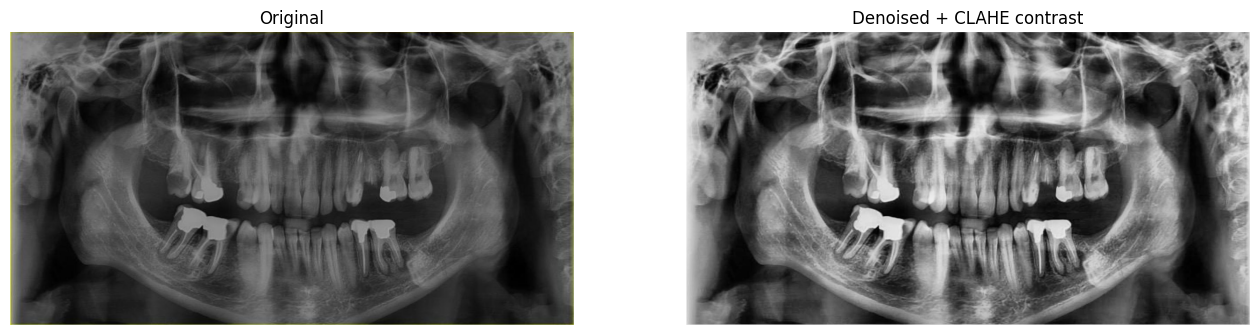

In [15]:
import cv2
import matplotlib.pyplot as plt
from ml.preprocess import preprocess_image

# Take one raw Kaggle image and show it before and after preprocessing.
raw_path = sorted(Path("/content/kaggle").rglob("valid/images/*.jpg"))[0]
raw = cv2.imread(str(raw_path))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].imshow(cv2.cvtColor(raw, cv2.COLOR_BGR2RGB)); axes[0].set_title("Original")
axes[1].imshow(cv2.cvtColor(preprocess_image(raw), cv2.COLOR_BGR2RGB)); axes[1].set_title("Denoised + CLAHE contrast")
for ax in axes: ax.axis("off")
plt.show()

## 4. Train YOLOv8

* `RUN_NAME` - give every experiment its own name (`smartdent_v2`, `smartdent_v3_dentex`, ...).
  Results go to separate folders in Drive, so older runs are never overwritten.
* Model: `yolov8s` (small). `yolov8m` is more accurate but about twice as slow.
* `IMGSZ = 1024` - v1 used 640. Panoramic X-rays are wide and caries and the bone-loss line are thin,
  so a larger input keeps more detail. It is slower, so the batch is 4.
* `hsv_h=0, hsv_s=0` - no colour augmentation, because X-rays are grey.
* `patience=15` - stops early if the model stops improving for 15 epochs.

One epoch takes several minutes. If Colab disconnects, re-run the whole notebook: this cell will
**resume** from the last saved epoch in Drive (keep the same `RUN_NAME`).

In [ ]:
from ultralytics import YOLO

import os, gc, torch
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"   # less wasted GPU memory
gc.collect(); torch.cuda.empty_cache()                                # free memory left by earlier runs

RUN_NAME = "smartdent_v3_dentex" if USE_DENTEX else "smartdent_v2"
MODEL = "yolov8s.pt"   # try "yolov8m.pt" for a bigger model (slower)
IMGSZ = 1024           # v1 used 640
BATCH = 4              # images per step. If you get "CUDA out of memory", lower this to 2.
last_checkpoint = RUNS_DIR / RUN_NAME / "weights" / "last.pt"

if last_checkpoint.exists():
    print("Resuming training from", last_checkpoint)
    model = YOLO(str(last_checkpoint))
    try:
        model.train(resume=True, batch=BATCH)
    except AssertionError:
        print("Training already finished. Go on to step 5.")
else:
    model = YOLO(MODEL)                     # starts from weights pre-trained on everyday photos
    model.train(
        data="/content/prepared/data.yaml",
        epochs=60,
        imgsz=IMGSZ,
        batch=BATCH,
        patience=15,
        hsv_h=0.0, hsv_s=0.0,               # X-rays have no colour
        fliplr=0.5,                         # left/right mirror is fine for panoramic X-rays
        seed=42,
        project=str(RUNS_DIR),
        name=RUN_NAME,
        exist_ok=True,
    )

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Resuming training from /content/drive/MyDrive/smartdent/runs/smartdent_v2/weights/last.pt
Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/prepared/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, e

In [ ]:
# Training curves: loss going down and mAP going up means the model is learning.
from IPython.display import Image, display
display(Image(filename=str(RUNS_DIR / RUN_NAME / "results.png"), width=1000))

## 5. Evaluate on the test set

The test X-rays were never seen during training. YOLO reports, per class:

* **Precision** - of the boxes the model drew, how many were correct.
* **Recall (= sensitivity)** - of the real findings, how many the model found.
* **mAP50** - average precision when a box counts as correct if it overlaps the true box by 50%.
* **mAP50-95** - the same, averaged over stricter overlaps (50% to 95%).

In [ ]:
import json
import pandas as pd
from ml import CLASS_NAMES

BEST_WEIGHTS = RUNS_DIR / RUN_NAME / "weights" / "best.pt"
best_model = YOLO(str(BEST_WEIGHTS))
test_metrics = best_model.val(data="/content/prepared/data.yaml", split="test", imgsz=IMGSZ, batch=BATCH,
                              project=str(RUNS_DIR), name=f"test_eval_{RUN_NAME}", exist_ok=True)

rows = []
for i, class_id in enumerate(test_metrics.box.ap_class_index):
    precision, recall, map50, map50_95 = test_metrics.box.class_result(i)
    rows.append({"class": CLASS_NAMES[class_id], "precision": precision, "recall (sensitivity)": recall,
                 "mAP50": map50, "mAP50-95": map50_95})
rows.append({"class": "ALL", "precision": test_metrics.box.mp, "recall (sensitivity)": test_metrics.box.mr,
             "mAP50": test_metrics.box.map50, "mAP50-95": test_metrics.box.map})
box_table = pd.DataFrame(rows).set_index("class").round(3)
box_table.to_csv(DRIVE_DIR / f"test_box_metrics_{RUN_NAME}.csv")
box_table

In [ ]:
# Confusion matrix: rows = what the model predicted, columns = the truth.
# "background" means a missed finding (column) or a false alarm (row).
display(Image(filename=str(Path(test_metrics.save_dir) / "confusion_matrix_normalized.png"), width=700))

### Per-X-ray sensitivity, specificity and accuracy

Dentists ask "does this X-ray show the condition?". For each class we count an X-ray as **flagged** if the
model draws at least one box of that class above that class's confidence threshold.
This check ignores how well the box overlaps, which is fairer for bone loss (a long band whose box size varies a lot).

* **Sensitivity** - of X-rays that have the condition, how many were flagged.
* **Specificity** - of X-rays that don't, how many were left clean.
* **Accuracy** - share of X-rays where the yes/no answer was right.

The model is run once with a very low threshold (0.01). Then the table below shows sensitivity and
specificity at several thresholds, and for each class we keep the **highest threshold that still reaches
`TARGET_SENSITIVITY`**. A lower threshold finds more findings but gives more false alarms; for a tool
that a dentist double-checks, missing less is usually worth a few more false alarms.

**Important:** picking thresholds on the test set makes the test score look a bit better than it is. For
the final report, pick them on the validation set (`SPLIT_FOR_THRESHOLDS = "val"`), then report test.

In [ ]:
from ml.evaluate import image_level_metrics, worst_images, threshold_sweep, pick_thresholds, flagged_classes

TARGET_SENSITIVITY = 0.80          # what we want per class, per X-ray
SPLIT_FOR_THRESHOLDS = "val"       # choose thresholds on val, report on test

def read_truth(image_path, width, height):
    """Load the true boxes of one image, converted to pixel corners."""
    label_path = image_path.parent.parent / "labels" / (image_path.stem + ".txt")
    truths = []
    for line in label_path.read_text().splitlines():
        cls, cx, cy, w, h = line.split()
        cx, cy, w, h = float(cx) * width, float(cy) * height, float(w) * width, float(h) * height
        truths.append((int(cls), (cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2)))
    return truths

def predict_split(split):
    """Run the model on one split with a very low threshold. Returns {path: (truths, predictions)}."""
    images = sorted(Path(f"/content/prepared/{split}/images").glob("*.jpg"))
    found = {}
    for result in best_model.predict(source=[str(p) for p in images], conf=0.01, imgsz=IMGSZ,
                                     stream=True, verbose=False):
        height, width = result.orig_shape
        predictions = [(int(c), tuple(b), float(s)) for c, b, s in
                       zip(result.boxes.cls.tolist(), result.boxes.xyxy.tolist(), result.boxes.conf.tolist())]
        found[result.path] = (read_truth(Path(result.path), width, height), predictions)
    return found

# 1) Choose one threshold per class.
sweep = pd.DataFrame(threshold_sweep(predict_split(SPLIT_FOR_THRESHOLDS)))
display(sweep.pivot(index="threshold", columns="class", values=["sensitivity", "specificity"]).round(3))
THRESHOLDS = pick_thresholds(sweep.to_dict("records"), TARGET_SENSITIVITY)
print("Chosen thresholds:", {CLASS_NAMES[c]: t for c, t in THRESHOLDS.items()})
(DRIVE_DIR / f"thresholds_{RUN_NAME}.json").write_text(json.dumps({CLASS_NAMES[c]: t for c, t in THRESHOLDS.items()}, indent=2))

# 2) Score the test set with those thresholds.
per_image_raw = predict_split("test")
per_image = {path: (truths, [p for p in preds if p[2] >= THRESHOLDS[p[0]]])
             for path, (truths, preds) in per_image_raw.items()}
pairs = [({c for c, _ in t}, {c for c, _, _ in p}) for t, p in per_image.values()]
xray_table = pd.DataFrame(image_level_metrics(pairs)).T.round(3)
xray_table.to_csv(DRIVE_DIR / f"test_xray_metrics_{RUN_NAME}.csv")
xray_table

### Compare runs

Every run saved its scores to Drive under its own name. This table puts them side by side
(v1 files from before this notebook are called `test_xray_metrics.csv` / `test_box_metrics.csv`).
Keep the run with the best **sensitivity** without losing too much **specificity**, and check Bone Loss
did not get worse when DENTEX was added.

In [ ]:
def load_runs(prefix):
    """Read every saved metrics CSV that starts with prefix. Returns one table, one row per (run, class)."""
    tables = []
    for csv in sorted(DRIVE_DIR.glob(f"{prefix}*.csv")):
        run = csv.stem.replace(prefix, "").lstrip("_") or "smartdent_v1"
        tables.append(pd.read_csv(csv, index_col=0).assign(run=run))
    return pd.concat(tables).reset_index().rename(columns={"index": "class"}) if tables else None

xray_runs = load_runs("test_xray_metrics")
display(xray_runs.pivot(index="class", columns="run", values=["sensitivity", "specificity"]).round(3))
box_runs = load_runs("test_box_metrics")
display(box_runs.pivot(index="class", columns="run", values=["recall (sensitivity)", "mAP50"]).round(3))

## 6. Error analysis: where does the model fail?

The X-rays with the most mistakes. **Green** = true finding, **red** = model prediction.
Look for patterns: very small caries? faint bone loss? blurry images? This goes into your report as limitations.

In [ ]:
COLOURS_TRUE, COLOURS_PRED = (0, 200, 0), (0, 0, 255)

def draw_case(path, truths, predictions):
    """Draw true boxes (green) and predicted boxes (red, with label and confidence)."""
    image = cv2.imread(path)
    for cls, (x1, y1, x2, y2) in truths:
        cv2.rectangle(image, (int(x1), int(y1)), (int(x2), int(y2)), COLOURS_TRUE, 3)
    for cls, (x1, y1, x2, y2), score in predictions:
        cv2.rectangle(image, (int(x1), int(y1)), (int(x2), int(y2)), COLOURS_PRED, 2)
        cv2.putText(image, f"{CLASS_NAMES[cls]} {score:.2f}", (int(x1), int(y1) - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, COLOURS_PRED, 2)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

worst = worst_images(per_image, top=6)
fig, axes = plt.subplots(3, 2, figsize=(20, 16))
for ax, (path, missed, false_alarms) in zip(axes.flat, worst):
    ax.imshow(draw_case(path, *per_image[path]))
    ax.set_title(f"{Path(path).name}: {missed} missed, {false_alarms} false alarms")
    ax.axis("off")
plt.tight_layout()
plt.savefig(DRIVE_DIR / "error_analysis.png", dpi=80)
plt.show()

# Which classes are missed most often?
from ml.evaluate import match_boxes
missed_per_class = {name: 0 for name in CLASS_NAMES}
for truths, predictions in per_image.values():
    for cls, name in enumerate(CLASS_NAMES):
        _, missed, _ = match_boxes([t for t in truths if t[0] == cls], [p for p in predictions if p[0] == cls])
        missed_per_class[name] += missed
print("Missed true boxes per class:", missed_per_class)

## 7. Export the trained model

`best.pt` is the trained model. Put it in the SmartDent project folder as `models/best.pt`;
the web app (Phase 5) loads it from there. A copy also stays in your Drive.

Also download `thresholds.json`: it has the confidence threshold per class chosen in step 5.
The web app should use these instead of one threshold for every class.

**Only export the run you decided to keep** (see "Compare runs").

In [ ]:
import shutil
from google.colab import files

export_path = DRIVE_DIR / "best.pt"
shutil.copy(BEST_WEIGHTS, export_path)
thresholds_path = DRIVE_DIR / "thresholds.json"
shutil.copy(DRIVE_DIR / f"thresholds_{RUN_NAME}.json", thresholds_path)
print("Saved to Drive:", export_path, thresholds_path)
files.download(str(export_path))
files.download(str(thresholds_path))